# Stage 12: Data foundation

This stage replaces 25 hand-picked survivors with what an investor could really have known each
month: every stock that traded, including failures, and each company's results from the moment they
were published. Nothing here looks for a signal. Return comparisons use the development period only.

The pass marks in the first code cell were fixed before any of the checks below were run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import research
from pmo import universe as un
from pmo.config import PROCESSED_DIR, RAW_DIR
from pmo.pipeline import load
from pmo.plotting import FIGURES, MUTED, PALETTE, apply_style

apply_style()
PASS_MARKS = {
    "parsed": 0.95,            # filings yielding revenue, profit and shares
    "fresh": 0.95,             # universe stock-months with a filing under 200 days old
    "share_jumps": 0.001,      # month-on-month share jumps no split explains
    "official_overlap": 0.80,  # overlap with published Nifty 200 lists
    "tracking_corr": 0.98,     # cap-weighted universe vs Nifty 200 total return, monthly
    "tracking_error": 0.03,    # same comparison, annualized
    "yahoo_gap": 0.002,        # median absolute monthly return gap vs Yahoo
}
FRESH_DAYS = 200
DELISTING_LOSS = 0.30
SAMPLE_DAY = pd.Timestamp("2018-06-29")

panel = pd.read_parquet(PROCESSED_DIR / "nse_panel.parquet",
                        columns=["date", "symbol", "isin", "series", "close", "value"])
daily = pd.read_parquet(PROCESSED_DIR / "nse_daily_returns.parquet")
actions = pd.read_parquet(PROCESSED_DIR / "nse_actions.parquet")
filings = pd.read_parquet(PROCESSED_DIR / "fundamentals.parquet")
index = pd.read_parquet(PROCESSED_DIR / "filing_index.parquet")
universe = pd.read_parquet(PROCESSED_DIR / "universe_monthly.parquet")
overlap = pd.read_csv(PROCESSED_DIR / "universe_overlap.csv")
indices = pd.read_parquet(RAW_DIR / "total_return_indices.parquet")
print(f"Daily rows: {len(panel):,}, stocks: {panel['symbol'].nunique():,}, "
      f"{panel['date'].min():%b %Y} to {panel['date'].max():%b %Y}")
print(f"Filings listed: {len(index):,}, parsed: {len(filings):,}")

Daily rows: 7,206,872, stocks: 3,886, Jun 2010 to Nov 2026
Filings listed: 18,489, parsed: 17,510


## 1. Does the data include the stocks that failed?

The old list held 25 companies chosen today, so all of them had survived. A fair test needs every
stock that was large at the time, including those that later vanished.

In [2]:
month_ends = sorted(universe["month"].unique())
last_full_month = pd.Timestamp("2026-10-31")
members = universe[universe["month"] <= last_full_month]
last_traded = panel.groupby("symbol", observed=True)["date"].max()
final_day = panel["date"].max()
ever = members["symbol"].unique()
gone = last_traded.reindex(ever) < final_day - pd.Timedelta(days=30)
final_members = set(members.loc[members["month"] == last_full_month, "symbol"])
print(f"Stocks ever in the universe: {len(ever)}")
print(f"  no longer trading: {gone.sum()}")
print(f"  trading but dropped out of the top 200: {len(ever) - gone.sum() - len(final_members)}")
print(f"  in the universe now: {len(final_members)}")
print("Examples no longer trading:", ", ".join(sorted(gone[gone].index)[:14]))

Stocks ever in the universe: 531
  no longer trading: 84
  trading but dropped out of the top 200: 247
  in the universe now: 200
Examples no longer trading: 3IINFOTECH, ABGSHIP, ABIRLANUVO, ALBK, ALOKTEXT, AMTEKAUTO, ANDHRABANK, BHARATFIN, BRFL, CAIRN, CAPF, CASTEXTECH, CASTROL, CMC


## 2. Were the published dates respected?

Each filing keeps the exchange's own broadcast time. Share counts are then rebuilt using only filings
published before each month end. The strongest check is to delete everything after a date and confirm
that date's universe doesn't change.

In [3]:
parsed_share = filings[["revenue", "net_profit", "shares"]].notna().all(axis=1).mean()
early = (filings["published"] < filings["quarter_end"]).sum()
lag = (filings["published"] - filings["quarter_end"]).dt.days
print(f"Filings with revenue, profit and shares: {parsed_share:.1%}")
print(f"Published before their quarter ended: {early}")
print(f"Days from quarter end to publication: median {lag.median():.0f}, 90th percentile {lag.quantile(.9):.0f}")

closes = panel.loc[panel["date"] == SAMPLE_DAY, ["date", "symbol", "close"]]
closes = closes.astype({"symbol": object, "date": "datetime64[ns]"})
full = un.market_caps(closes, filings, actions).set_index("symbol")["market_cap"]
known_filings = filings[filings["published"] < SAMPLE_DAY]
known_actions = actions[actions["date"] <= SAMPLE_DAY]
blind = un.market_caps(closes, known_filings, known_actions).set_index("symbol")["market_cap"]
same_caps = np.allclose(full.dropna().sort_index(), blind.dropna().sort_index())
stored = pd.read_parquet(PROCESSED_DIR / "nse_liquidity.parquet")
recent = panel[(panel["date"] <= SAMPLE_DAY)
               & (panel["date"] >= SAMPLE_DAY - pd.Timedelta(days=200))].copy()
recent["symbol"] = recent["symbol"].astype(object)
rebuilt = un.liquidity(recent).loc[SAMPLE_DAY]
top = stored.loc[SAMPLE_DAY].nlargest(100).index
same_liquidity = np.allclose(stored.loc[SAMPLE_DAY, top], rebuilt.reindex(top), equal_nan=True, rtol=1e-6)
print(f"Market caps unchanged when the future is deleted: {same_caps}")
print(f"Liquidity unchanged when the future is deleted: {same_liquidity}")

Filings with revenue, profit and shares: 98.7%
Published before their quarter ended: 0
Days from quarter end to publication: median 38, 90th percentile 59


Market caps unchanged when the future is deleted: True
Liquidity unchanged when the future is deleted: True


## 3. Are the share counts and market values believable?

Filings contain typing errors, and one 1,000-times error would put a mid-sized company at number one.
Any jump in shares that no split explains is held back until a second filing agrees.

In [4]:
levels = un.share_levels(actions)
check = members.merge(panel[["date", "symbol", "close"]].astype({"symbol": object}), on=["date", "symbol"])
check = check.sort_values(["symbol", "date"]).reset_index(drop=True)
check["units"] = check["market_cap"] / check["close"] / un._level_on(check, "date", levels)
check["jump"] = check.groupby("symbol")["units"].pct_change()
check["gap"] = check.groupby("symbol")["date"].diff().dt.days
share_jumps = ((check["gap"] < 40) & (check["jump"].abs() > 2)).mean()
print(f"Unexplained share jumps above 200%: {share_jumps:.3%} of stock-months")

latest = filings.dropna(subset=["shares"]).assign(
    filed=lambda t: t["published"].dt.normalize().astype("datetime64[ns]")).sort_values("filed")
fresh = pd.merge_asof(members.sort_values("date"), latest[["symbol", "filed"]], left_on="date",
                      right_on="filed", by="symbol", allow_exact_matches=False)
fresh_share = ((fresh["date"] - fresh["filed"]).dt.days <= FRESH_DAYS).mean()
print(f"Universe stock-months with a filing under {FRESH_DAYS} days old: {fresh_share:.1%}")

leaders = members[members["month"].isin(pd.to_datetime(
    ["2012-12-31", "2016-12-31", "2021-12-31", "2026-10-31"])) & (members["rank"] <= 8)]
print(leaders.pivot_table(index="rank", columns="month", values="symbol", aggfunc="first")
      .rename(columns=lambda c: f"{c:%b %Y}").to_string())

Unexplained share jumps above 200%: 0.005% of stock-months
Universe stock-months with a filing under 200 days old: 95.2%
month   Dec 2012  Dec 2016    Dec 2021    Oct 2026
rank                                              
1.0     RELIANCE       TCS    RELIANCE    RELIANCE
2.0          TCS  RELIANCE         TCS  BHARTIARTL
3.0         ONGC  HDFCBANK    HDFCBANK    HDFCBANK
4.0          ITC       ITC        INFY   ICICIBANK
5.0    COALINDIA      ONGC  HINDUNILVR         TCS
6.0     HDFCBANK      INFY   ICICIBANK        SBIN
7.0         SBIN      HDFC        HDFC  BAJFINANCE
8.0         INFY      SBIN  BAJFINANCE          LT


## 4. How close is the rule to the official index?

Official Nifty 200 lists exist only as occasional snapshots, so the universe uses a published rule
instead: the 200 largest stocks each month among the 400 most traded. An exact match isn't expected,
since the index uses free-float size and has its own eligibility tests. The real question is whether
the two cover the same part of the market.

            same  in_200
list                    
Nifty 100  0.838   0.927
Nifty 200  0.862   0.862
Snapshots compared: 28


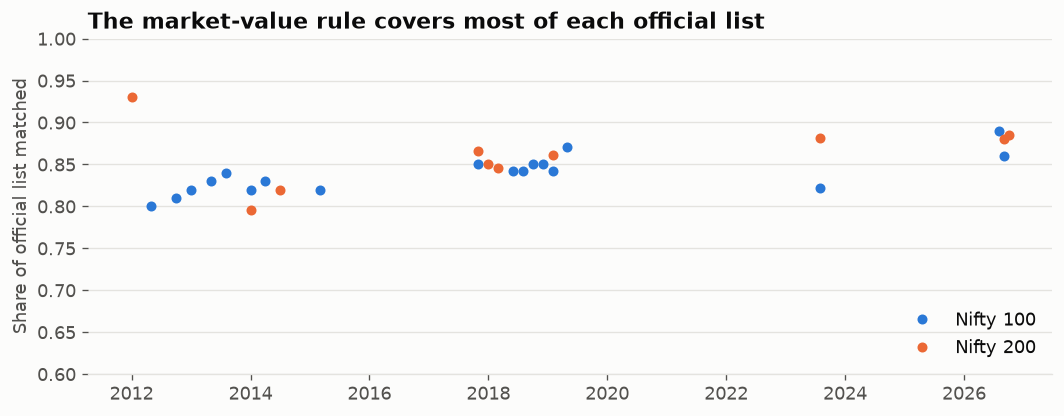

In [5]:
lists = overlap.groupby("list")[["same", "in_200"]].mean()
print(lists.round(3).to_string())
print(f"Snapshots compared: {len(overlap)}")
official_overlap = overlap.loc[overlap["list"] == "Nifty 200", "same"].mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
for colour, (name, group) in zip(PALETTE, overlap.groupby("list")):
    dates = pd.to_datetime(group["snap"].astype(str), format="%Y%m")
    ax.plot(dates, group["same"], "o", ms=5, color=colour, label=name)
ax.set_ylim(0.6, 1)
ax.set_ylabel("Share of official list matched")
ax.legend(frameon=False, loc="lower right")
ax.set_title("The market-value rule covers most of each official list")
fig.tight_layout()
fig.savefig(FIGURES / "12_official_overlap.png", dpi=150, bbox_inches="tight")

## 5. Do returns match independent sources? (development period)

Two checks. Returns built from raw exchange files should agree with Yahoo for the 25 stocks we already
trust. A market-value-weighted portfolio of the universe should also closely follow the official Nifty
200 total return index, which is calculated without any of this project's code.

In [6]:
monthly = un.monthly_total_returns(daily)
stressed = un.monthly_total_returns(daily, DELISTING_LOSS)
development = research.window(monthly, "development")
stressed = research.window(stressed, "development")
months = development.index

dataset = load()
stocks = [s for s in dataset.universe["symbol"] if s in development]
yahoo = research.window(dataset.returns[stocks], "development")
shared = months.intersection(yahoo.index)
yahoo_gap = (development.loc[shared, stocks] - yahoo.loc[shared]).abs().stack().median()
print(f"Median absolute monthly gap vs Yahoo: {yahoo_gap:.3%}")

held = universe.pivot_table(index="month", columns="symbol", values="market_cap", aggfunc="first")
held = held.shift(1).reindex(months)
held.columns = held.columns.astype(object)
returns = development.reindex(columns=held.columns)
stress_returns = stressed.reindex(columns=held.columns)
in_universe = held.notna() & returns.notna()
equal = returns.where(in_universe).mean(axis=1)
equal_stressed = stress_returns.where(in_universe).mean(axis=1)
weights = held.where(in_universe)
weights = weights.div(weights.sum(axis=1), axis=0)
capped = (weights * returns).sum(axis=1, min_count=1)

official = indices.ffill().resample("ME").last().pct_change()
official.index = official.index.normalize()
official = research.window(official, "development")
pairs = pd.DataFrame({"mine": capped, "nifty200": official["NIFTY 200"]}).dropna()
tracking_corr = pairs.corr().iloc[0, 1]
tracking_error = (pairs["mine"] - pairs["nifty200"]).std() * np.sqrt(12)
print(f"Value-weighted universe vs Nifty 200: correlation {tracking_corr:.3f}, "
      f"tracking error {tracking_error:.1%}, months {len(pairs)}")

Median absolute monthly gap vs Yahoo: 0.000%
Value-weighted universe vs Nifty 200: correlation 0.992, tracking error 2.3%, months 131


## 6. How much did survivorship flatter the old universe? (development period)

This isn't a strategy result. It shows how far a list of today's winners overstates what was
achievable, which also explains why results from earlier stages can't be compared with later ones.

Feb 2011 to Dec 2021
25 survivors, equal weight                   20.0%
Point-in-time top 200, equal weight          13.4%
Same, 30% loss when a stock stops trading    13.1%
Point-in-time top 200, value weight          12.5%
Nifty 200 total return                       12.9%
Nifty 50 total return                        12.5%


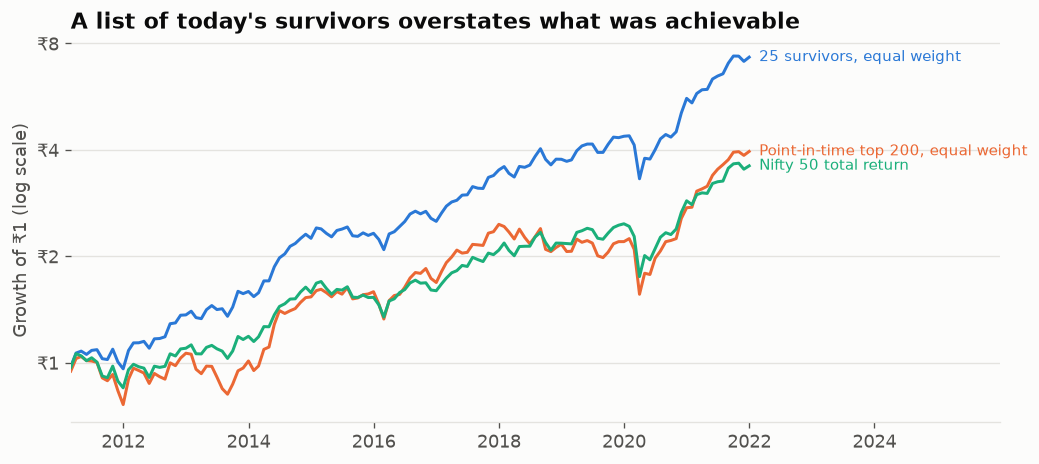

In [7]:
def yearly(series):
    series = series.dropna()
    return (1 + series).prod() ** (12 / len(series)) - 1


survivors = research.window(dataset.returns[stocks], "development").mean(axis=1)
start = max(s.dropna().index.min() for s in (equal, survivors, official["NIFTY 50"]))
compare = {
    "25 survivors, equal weight": survivors,
    "Point-in-time top 200, equal weight": equal,
    f"Same, {DELISTING_LOSS:.0%} loss when a stock stops trading": equal_stressed,
    "Point-in-time top 200, value weight": capped,
    "Nifty 200 total return": official["NIFTY 200"],
    "Nifty 50 total return": official["NIFTY 50"],
}
summary = pd.Series({k: yearly(v.loc[start:]) for k, v in compare.items()}, name="CAGR")
print(f"{start:%b %Y} to {months.max():%b %Y}")
print(summary.map("{:.1%}".format).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
lines = ["25 survivors, equal weight", "Point-in-time top 200, equal weight", "Nifty 50 total return"]
for colour, name in zip(PALETTE, lines):
    growth = (1 + compare[name].loc[start:].fillna(0)).cumprod()
    ax.plot(growth, color=colour, lw=1.8)
    ax.annotate(name, (growth.index[-1], growth.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=colour, fontsize=9)
ax.set_yscale("log")
ax.set_yticks([1, 2, 4, 8], labels=["₹1", "₹2", "₹4", "₹8"])
ax.minorticks_off()
ax.set_ylabel("Growth of ₹1 (log scale)")
ax.set_title("A list of today's survivors overstates what was achievable")
ax.set_xlim(start, months.max() + pd.DateOffset(years=4))
fig.tight_layout()
fig.savefig(FIGURES / "12_survivorship.png", dpi=150, bbox_inches="tight")

## 7. Stage gate

In [8]:
gate = pd.DataFrame([
    ("Filings parsed", parsed_share, f">= {PASS_MARKS['parsed']:.0%}", parsed_share >= PASS_MARKS["parsed"]),
    ("Universe has fresh filings", fresh_share, f">= {PASS_MARKS['fresh']:.0%}", fresh_share >= PASS_MARKS["fresh"]),
    ("No filing dated before quarter end", early, "= 0", early == 0),
    ("Unchanged when the future is deleted", same_caps and same_liquidity, "True", same_caps and same_liquidity),
    ("Unexplained share jumps", share_jumps, f"<= {PASS_MARKS['share_jumps']:.1%}", share_jumps <= PASS_MARKS["share_jumps"]),
    ("Overlap with official Nifty 200", official_overlap, f">= {PASS_MARKS['official_overlap']:.0%}", official_overlap >= PASS_MARKS["official_overlap"]),
    ("Correlation with Nifty 200", tracking_corr, f">= {PASS_MARKS['tracking_corr']}", tracking_corr >= PASS_MARKS["tracking_corr"]),
    ("Tracking error vs Nifty 200", tracking_error, f"<= {PASS_MARKS['tracking_error']:.0%}", tracking_error <= PASS_MARKS["tracking_error"]),
    ("Monthly return gap vs Yahoo", yahoo_gap, f"<= {PASS_MARKS['yahoo_gap']:.1%}", yahoo_gap <= PASS_MARKS["yahoo_gap"]),
], columns=["Check", "Result", "Pass mark", "Passed"])
print(gate.to_string(index=False))
print("All passed:", bool(gate["Passed"].all()))

                               Check    Result Pass mark  Passed
                      Filings parsed  0.986865    >= 95%    True
          Universe has fresh filings  0.951693    >= 95%    True
  No filing dated before quarter end         0       = 0    True
Unchanged when the future is deleted      True      True    True
             Unexplained share jumps  0.000053   <= 0.1%    True
     Overlap with official Nifty 200    0.8615    >= 80%    True
          Correlation with Nifty 200  0.991728   >= 0.98    True
         Tracking error vs Nifty 200  0.023316     <= 3%    True
         Monthly return gap vs Yahoo       0.0   <= 0.2%    True
All passed: True
